# Продуктовая аналитика маркетплейса

 Вы — аналитик данных, и сейчас идёте в стартап, который создает новый маркетплейс. Он недавно появился на рынке и занимается продажей новых товаров из Бразилии, которые только начинают поступать в продажу.  
  
 Продакт-менеджер Петя переживает за свой продукт, так как выручка маркетплейса стоит на месте уже несколько месяцев. Он предложил вам полную свободу действий. Главное — чтобы метрики росли, а мы не причиняли неудобства клиентам, ведь Петя заботится об их опыте. 



## Задачи:
**Задача 1:** Оценить месячный retention в оформление заказа с помощью когортного анализа.  
**Задача 2:** Определить, существует ли product/market fit у этого маркетплейса.  
**Задача 3:** Определить 5 основных метрик, на которых продакту можно сконцентрироваться, чтобы максимизировать прибыль компании.  
**Задача 4:** Выбрать одну из 3 основных гипотез с помощью фреймворка ICE.  
**Задача 5:** Сформулировать нужные метрики, на которые ваша гипотеза должна повлиять.  
**Задача 6:** Сформулировать выводы о проделанной работе и составить отчет.

## Описание данных:
**olist_customers_dataset.csv** — таблица с уникальными идентификаторами пользователей
- customer_id — позаказный идентификатор пользователя
- customer_unique_id — уникальный идентификатор пользователя (аналог номера паспорта)
- customer_zip_code_prefix — почтовый индекс пользователя
- customer_city — город доставки пользователя
- customer_state — штат доставки пользователя

**olist_orders_dataset.csv** —  таблица заказов
- order_id — уникальный идентификатор заказа (номер чека)
- customer_id — позаказный идентификатор пользователя
- order_status — статус заказа
- order_purchase_timestamp — время создания заказа
- order_approved_at — время подтверждения оплаты заказа
- order_delivered_carrier_date — время передачи заказа в логистическую службу
- order_delivered_customer_date — время доставки заказа
- order_estimated_delivery_date — обещанная дата доставки

**olist_order_items_dataset.csv** — товарные позиции, входящие в заказы
- order_id — уникальный идентификатор заказа (номер чека)
- order_item_id — идентификатор товара внутри одного заказа
- product_id — ид товара (аналог штрихкода)
- seller_id — ид производителя товара
- shipping_limit_date — максимальная дата доставки продавцом для передачи заказа партнеру по логистике
- price — цена за единицу товара
- freight_value — стоимость доставки

Пример структуры данных можно визуализировать по order_id == 00143d0f86d6fbd9f9b38ab440ac16f5

Уникальные статусы заказов в таблице **olist_orders_dataset**:
- created — создан;
- approved — подтверждён;
- invoiced — выставлен счёт;
- processing — в процессе сборки заказа;
- shipped — отгружён со склада;
- delivered — доставлен пользователю;
- unavailable — заказ отменён по причине недоступности товара;;
- canceled — отменён.

## Загрузка данных

In [78]:
# Имрпорт библиотек
import pandas as pd
import numpy as np
import seaborn as sns
import requests

from matplotlib import pyplot as plt
from matplotlib import colors as mcolors
from operator import attrgetter
from urllib.parse import urlencode

In [86]:
# Путь к файлам на Яндекс.Диске
path_customers = 'https://disk.yandex.ru/d/XFVA-klXC8NFrw'
path_orders = 'https://disk.yandex.ru/d/m7OG__pEoYos9A'
path_order_items = 'https://disk.yandex.ru/d/b_54RpFHQHQa4A'

In [76]:
# Функция для считывание файла с Яндекс.Диска (с открытым доступом)
# public_link - публичная ссылка на файл

def download_file(public_link):
    # 1. Запрашиваем у API прямую ссылку для скачивания
    base_url = 'https://cloud-api.yandex.net/v1/disk/public/resources/download?'
    final_url = base_url + urlencode(dict(public_key=public_link))
    response = requests.get(final_url)
    
    # 2. Извлекаем прямой URL из ответа
    download_url = response.json()['href']

    return download_url

In [84]:
# Считываем данные 'olist_customers_dataset.csv' с Яндекс.Диска
customers = pd.read_csv(download_file(path_customers))

In [3]:
# Выведем первые 3 строки customers
customers.head(3)

,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP


In [4]:
# Выведем общую информацию об customers
customers.info()

<class 'pandas.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 5 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   customer_id               99441 non-null  str  
 1   customer_unique_id        99441 non-null  str  
 2   customer_zip_code_prefix  99441 non-null  int64
 3   customer_city             99441 non-null  str  
 4   customer_state            99441 non-null  str  
dtypes: int64(1), str(4)
memory usage: 3.8 MB


In [5]:
# Проверим customers на наличие явных дубликатов
customers.duplicated().sum()

np.int64(0)

In [87]:
# Считываем данные 'olist_orders_dataset.csv' с Яндекс.Диска
# Преобразуем поля с датами в datetime
orders = pd.read_csv(download_file(path_orders), 
                    parse_dates=['order_purchase_timestamp', 
                                 'order_approved_at', 
                                 'order_delivered_carrier_date',
                                 'order_delivered_customer_date',
                                 'order_estimated_delivery_date']
                    )

In [88]:
# Выведем первые 3 строки orders
orders.head(3)

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04


In [8]:
# Выведем общую информацию об orders
orders.info()

<class 'pandas.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype         
---  ------                         --------------  -----         
 0   order_id                       99441 non-null  str           
 1   customer_id                    99441 non-null  str           
 2   order_status                   99441 non-null  str           
 3   order_purchase_timestamp       99441 non-null  datetime64[us]
 4   order_approved_at              99281 non-null  datetime64[us]
 5   order_delivered_carrier_date   97658 non-null  datetime64[us]
 6   order_delivered_customer_date  96476 non-null  datetime64[us]
 7   order_estimated_delivery_date  99441 non-null  datetime64[us]
dtypes: datetime64[us](5), str(3)
memory usage: 6.1 MB


**Замечание:** Есть пропуски в полях с датами, возможно, это связано с отмененными заказами.

In [9]:
# Проверим orders на наличие явных дубликатов
orders.duplicated().sum()

np.int64(0)

In [89]:
# Считаем данные 'olist_order_items_dataset.csv'
# Преобразуем поля с датами в datetime
order_items = pd.read_csv(download_file(path_order_items),
                         parse_dates=['shipping_limit_date'])

In [90]:
# Выведем первые 3 строки order_items
order_items.head(3)

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.9,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.9,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.0,17.87


In [12]:
# Выведем информацию об order_items
order_items.info()

<class 'pandas.DataFrame'>
RangeIndex: 112650 entries, 0 to 112649
Data columns (total 7 columns):
 #   Column               Non-Null Count   Dtype         
---  ------               --------------   -----         
 0   order_id             112650 non-null  str           
 1   order_item_id        112650 non-null  int64         
 2   product_id           112650 non-null  str           
 3   seller_id            112650 non-null  str           
 4   shipping_limit_date  112650 non-null  datetime64[us]
 5   price                112650 non-null  float64       
 6   freight_value        112650 non-null  float64       
dtypes: datetime64[us](1), float64(2), int64(1), str(3)
memory usage: 6.0 MB


In [13]:
# Проверим order_items на наличие явных дубликатов
order_items.duplicated().sum()

np.int64(0)

## Предобработка данных

In [14]:
# Обьеденим данные orders и customers по полю customer_id
data = pd.merge(orders,
                customers,
                on='customer_id')

In [15]:
# Удалим поля 'customer_id', 'customer_zip_code_prefix'
data = data.drop(columns=['customer_id', 'customer_zip_code_prefix'])

In [16]:
data.head()

,order_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,customer_unique_id,customer_city,customer_state
0,e481f51cbdc54678b7cc49136f2d6af7,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,7c396fd4830fd04220f754e42b4e5bff,sao paulo,SP
1,53cdb2fc8bc7dce0b6741e2150273451,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,af07308b275d755c9edb36a90c618231,barreiras,BA
2,47770eb9100c2d0c44946d9cf07ec65d,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,3a653a41f6f9fc3d2a113cf8398680e8,vianopolis,GO
3,949d5b44dbf5de918fe9c16f97b45f8a,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,7c142cf63193a1473d2e66489a9ae977,sao goncalo do amarante,RN
4,ad21c59c0840e6cb83a9ceb5573f8159,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,72632f0f9dd73dfee390c9b22eb56dd6,santo andre,SP


## Анализ данных

### Задача 1. Оценить месячный Retention с помощью когортного анализа.
Посчитаем retention по неотмененным заказам. Для расчетов будем использовать дату создания заказа - 'order_purchase_timestamp'.

In [17]:
# Уберем из данных заказы со статусами canceled и unavailable
non_cancelled_orders = data.query("order_status not in ['canceled', 'unavailable']")

In [18]:
# Извлечем месяц заказа из поля order_purchase_timestamp - дата создания заказа
non_cancelled_orders['order_period'] = non_cancelled_orders.order_purchase_timestamp.dt.to_period('M')

In [19]:
# Присвоим кагорты пользователям
non_cancelled_orders['cohort'] = non_cancelled_orders.groupby('customer_unique_id').order_period.transform('min')

In [20]:
# Рассчитываем номер периода (месячные периоды)
non_cancelled_orders['period_number_month'] = (non_cancelled_orders.order_period - non_cancelled_orders.cohort).apply(attrgetter('n'))                              

In [21]:
# Посчитаем количество уникальных пользователей в когортах по месецам
data_cohort = (non_cancelled_orders.groupby(['cohort', 'period_number_month'])
                                   .agg(count_customers=('customer_unique_id', 'nunique'))
                                   .reset_index()
              )

In [22]:
# Развернем таблицу так, чтобы индексами были когорты, а колонками — периоды (в месяцах).
pivot_cohort = data_cohort.pivot(index='cohort', 
                                 columns='period_number_month', 
                                 values='count_customers')

In [23]:
pivot_cohort

period_number_month,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,19,20
cohort,,,,,,,,,,,,,,,,,,,,
2016-09,2.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2016-10,290.0,NaN,NaN,NaN,NaN,NaN,1.0,NaN,NaN,1.0,NaN,1.0,NaN,1.0,NaN,1.0,NaN,1.0,2.0,2.0
2016-12,1.0,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2017-01,752.0,3.0,2.0,1.0,3.0,1.0,3.0,1.0,1.0,NaN,3.0,1.0,5.0,3.0,1.0,1.0,2.0,3.0,1.0,NaN
2017-02,1690.0,4.0,5.0,2.0,7.0,2.0,4.0,3.0,2.0,3.0,2.0,5.0,2.0,3.0,2.0,1.0,1.0,4.0,NaN,NaN
2017-03,2571.0,13.0,9.0,10.0,9.0,4.0,4.0,8.0,9.0,2.0,10.0,3.0,6.0,3.0,4.0,6.0,2.0,4.0,NaN,NaN
2017-04,2325.0,14.0,5.0,4.0,7.0,6.0,8.0,7.0,7.0,4.0,6.0,2.0,2.0,1.0,2.0,2.0,3.0,NaN,NaN,NaN
2017-05,3541.0,17.0,17.0,14.0,11.0,12.0,15.0,5.0,9.0,9.0,9.0,12.0,9.0,1.0,7.0,8.0,NaN,NaN,NaN,NaN
2017-06,3102.0,14.0,11.0,12.0,8.0,12.0,11.0,7.0,4.0,7.0,10.0,10.0,5.0,4.0,6.0,NaN,NaN,NaN,NaN,NaN


**Замечание:** По таблице видно, что до когорты '2017-01' в данных имеется большое количество пропусков. Также у нас пока нет данных за 1 месяц по когорте '2018-08'. Эти данные можно отбросить.

In [24]:
# Отфильтруем данные оставив когорты начиная с '2017-01' по '2018-07'
filtred_pivot_cohort = pivot_cohort.loc['2017-01':'2018-07', :]

In [25]:
# Извлечем размеры когорт (количество пользователей в 0 месяц)
cohort_size = filtred_pivot_cohort.iloc[:, 0]

In [26]:
# Построим матрицу retention
retention_matrix = filtred_pivot_cohort.divide(cohort_size, axis=0)

In [27]:
retention_matrix

period_number_month,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,19,20
cohort,,,,,,,,,,,,,,,,,,,,
2017-01,1.0,0.003989,0.002660,0.001330,0.003989,0.001330,0.003989,0.001330,0.001330,NaN,0.003989,0.001330,0.006649,0.003989,0.001330,0.001330,0.002660,0.003989,0.00133,NaN
2017-02,1.0,0.002367,0.002959,0.001183,0.004142,0.001183,0.002367,0.001775,0.001183,0.001775,0.001183,0.002959,0.001183,0.001775,0.001183,0.000592,0.000592,0.002367,NaN,NaN
2017-03,1.0,0.005056,0.003501,0.003890,0.003501,0.001556,0.001556,0.003112,0.003501,0.000778,0.003890,0.001167,0.002334,0.001167,0.001556,0.002334,0.000778,0.001556,NaN,NaN
2017-04,1.0,0.006022,0.002151,0.001720,0.003011,0.002581,0.003441,0.003011,0.003011,0.001720,0.002581,0.000860,0.000860,0.000430,0.000860,0.000860,0.001290,NaN,NaN,NaN
2017-05,1.0,0.004801,0.004801,0.003954,0.003106,0.003389,0.004236,0.001412,0.002542,0.002542,0.002542,0.003389,0.002542,0.000282,0.001977,0.002259,NaN,NaN,NaN,NaN
2017-06,1.0,0.004513,0.003546,0.003868,0.002579,0.003868,0.003546,0.002257,0.001289,0.002257,0.003224,0.003224,0.001612,0.001289,0.001934,NaN,NaN,NaN,NaN,NaN
2017-07,1.0,0.005233,0.003401,0.002355,0.002878,0.002093,0.003140,0.001047,0.001832,0.002616,0.002093,0.002878,0.001308,0.002616,NaN,NaN,NaN,NaN,NaN,NaN
2017-08,1.0,0.006780,0.003390,0.002663,0.003632,0.005327,0.002906,0.002663,0.001453,0.001453,0.002421,0.001937,0.001211,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2017-09,1.0,0.006871,0.005399,0.002945,0.004417,0.002209,0.002209,0.002454,0.002945,0.001718,0.002699,0.000736,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [28]:
# Посчитаем медиану retention 1 месяца
retention_matrix.iloc[:, 1].median()

np.float64(0.005056398288603656)

**Выводы:** Медиана retention 1-го месяца 0,51%, что является довольно низким показателем.

In [29]:
# Найдем когорту с самым высоким retention на 3-й месяц.
retention_matrix.iloc[:, 3].idxmax()

Period('2017-05', 'M')

**Выводы:** Самый высокий retention 3-го месяца в когорте '2017-05'

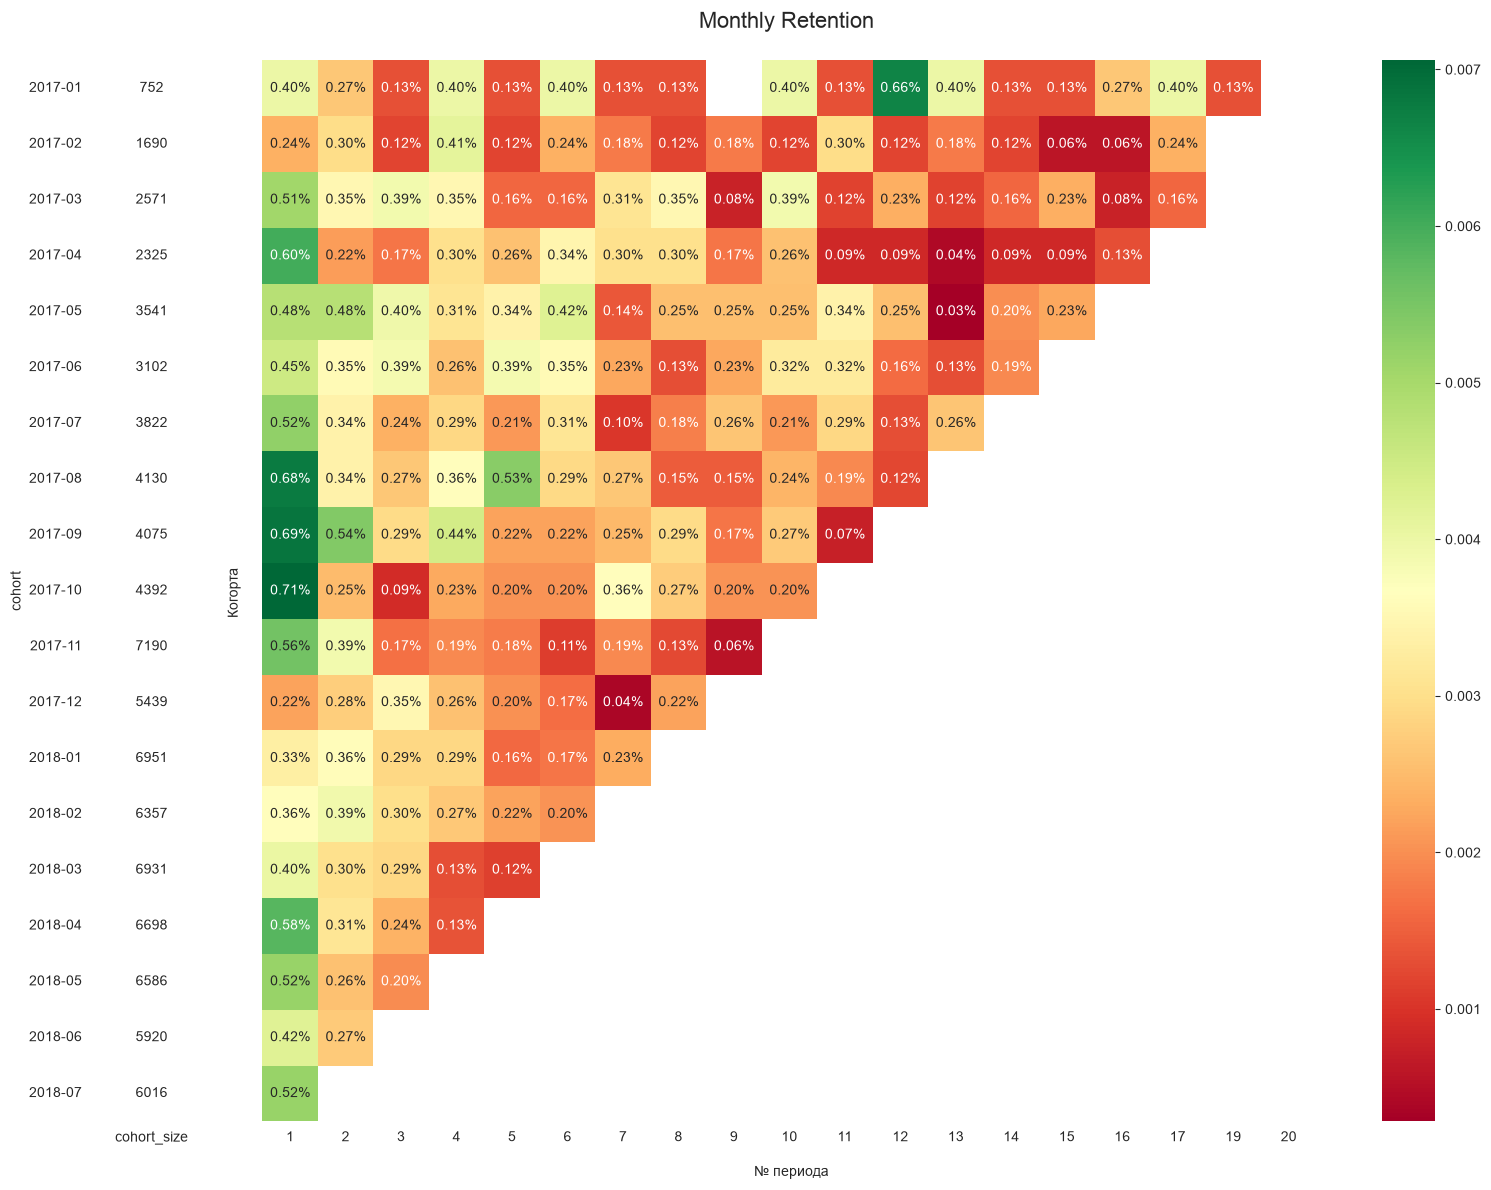

In [30]:
# Построим тепловую карту когортного анализа
with sns.axes_style("white"):
    fig, ax = plt.subplots(1, 2, figsize=(16, 12), sharey=True, gridspec_kw={'width_ratios': [1, 11]})

    # Тепловая карта для коэффициентов удержания
    sns.heatmap(retention_matrix.iloc[:, 1:],
                mask=retention_matrix.iloc[:, 1:].isnull(),
                annot=True,
                fmt='.2%',
                cmap='RdYlGn',
                ax=ax[1])
    ax[1].set_title('Monthly Retention \n', fontsize=16)
    ax[1].set(xlabel='\n № периода', ylabel='Когорта \n')

    # Тепловая карта для размеров когорт
    cohort_size_df = pd.DataFrame(cohort_size).rename(columns={0: 'cohort_size'})
    white_cmap = mcolors.ListedColormap(['white'])
    sns.heatmap(cohort_size_df,
                annot=True,
                cbar=False,
                fmt='g',
                cmap=white_cmap,
                ax=ax[0])

    fig.tight_layout()
    plt.savefig('images/retention_heatmap.png', dpi=150, bbox_inches='tight')
    plt.show()

**Выводы по задаче:** 
- Медиана retention 1-го месяца — 0,51%. Это означает, что из ~1000 новых клиентов возвращается всего около 5 человек. Для маркетплейса это критически низкий показатель: здоровая норма для e-commerce — 15–30% на второй месяц.
- Динамика retention по когортам не улучшается со временем: когорты 2018 года показывают те же значения, что и когорты 2017 года. Это говорит о том, что проблема носит системный, а не разовый характер — она не связана с отдельной акцией или сезонностью.
- Наибольший retention 3-го месяца зафиксирован в когорте 2017-05. Это может быть связано с ростом ассортимента или маркетинговой активностью в тот период. Однако даже этот «лучший» результат остаётся в пределах 0,4–0,5% — то есть выделить успешную практику не получается.
- Начиная с 12-го месяца retention падает практически до нуля. Клиенты не возвращаются даже спустя год, что подтверждает отсутствие долгосрочной лояльности.

**Итог:** продукт не удерживает клиентов ни в короткой, ни в длинной перспективе. Без роста retention любые инвестиции в привлечение трафика будут убыточны — стоимость привлечения (CAC) не окупается.

### Задача 2. Определить, наличие product/market fit.

Построим график медианы retention по месяцам.

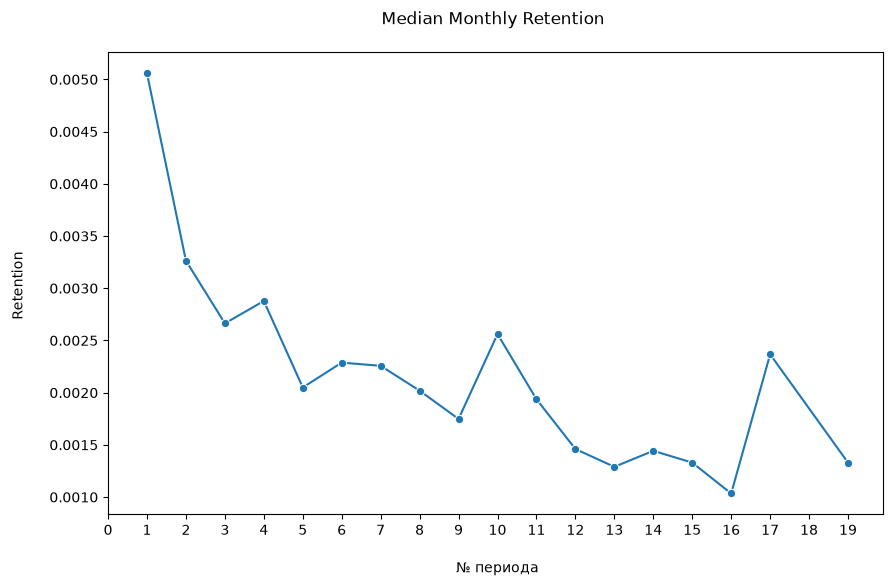

In [31]:
# Строим график медианы retention по месяцам
plt.figure(figsize=(10,6))
sns.lineplot(data=retention_matrix.iloc[:, 1:].median(), marker='o')
plt.title('Median Monthly Retention \n')
plt.xlabel('\n № периода')
plt.xticks(range(len(retention_matrix.columns)))
plt.ylabel('Retention \n')
plt.savefig('images/median_retention.png', dpi=150, bbox_inches='tight')
plt.show()

**Выводы:** PMF - фактически отсутствует. Retention 1-го месяца менее 1%. 

Посмотрим на количество клиентов, которые оформили более 1 заказа.

In [32]:
# Определяем процент пользователей по числу заказов.
non_cancelled_orders.groupby('customer_unique_id').order_id.count().value_counts(normalize=True)

order_id
1     0.969597
2     0.027919
3     0.001979
4     0.000305
5     0.000095
6     0.000053
7     0.000032
9     0.000011
16    0.000011
Name: proportion, dtype: float64

**Выводы:** Почти 97% всех клиентов оформили всего 1 заказ. Возмоджно причина в сроках доставки.

Рассмотрим процент заказов, которые доставляются с задержкой, среднее время этой задержки и среднее время доставки заказа с момента офорсления.

In [33]:
# Посчитаем время задержки заказа (в днях) и время доставки заказа (в днях)
delivered_orders = non_cancelled_orders.query("order_status == 'delivered'")
delivered_orders['delivery_delay_days'] = ((delivered_orders.order_delivered_customer_date - delivered_orders.order_estimated_delivery_date)
                                            .dt.days
                                          )
delivered_orders['delivery_days'] = ((delivered_orders.order_delivered_customer_date - delivered_orders.order_approved_at)
                                      .dt.days
                                    )

In [34]:
# Посчитаем медиану времени доставки заказов в днях
delivered_orders['delivery_days'].median()

np.float64(9.0)

In [35]:
# Посчитаем медиану времени опоздания заказов (в днях) для тех заказов, которые опоздали ('delivery_delay_days' > 0)
delivered_orders[delivered_orders['delivery_delay_days'] > 0]['delivery_delay_days'].median()

np.float64(7.0)

In [36]:
# Посчитаем процент задержавшихся заказов от общего числа доставленных заказов
count_delay_orders = delivered_orders[delivered_orders['delivery_delay_days'] > 0]['order_id'].count()
percent_delay = count_delay_orders / delivered_orders['order_id'].count()
percent_delay

np.float64(0.0677252845208234)

**Выводы:** 
- Среднее время доставки заказов — 9 дней.
- При задержке доставки она в среднем увеличивается на 7 дней.
- Доля задержанных заказов среди всех доставленных составляет 6,77%.

Проанализируем, сколько времени обычно требуется для передачи заказа в логистическую службу после его оплаты и сколько времени занимает доставка заказа клиенту после того, как он попал в логистическую службу. Возьмем выборку с доставленными заказами.

In [37]:
# Посчитаем колько времени (дней) требуется для передачи заказа в логистическую службу после его оплаты
delivered_orders['order_assembly_time_days'] = (delivered_orders.order_delivered_carrier_date
                                                - delivered_orders.order_approved_at).dt.days

# Посчитаем сколько времени (дней) занимает доставка заказа клиенту после того, как он попал в логистическую службу
delivered_orders['carrier_transit_time_days'] = (delivered_orders.order_delivered_customer_date
                                                 - delivered_orders.order_delivered_carrier_date).dt.days

In [38]:
# Создадим поле 'is_delay', показывающе опоздание заказа при доставке. 
# Предварительно удалим пропуски в 'delivery_delay_days'
delivered_orders['is_delay'] = pd.cut(delivered_orders.delivery_delay_days.dropna(),
                                      [-np.inf,0,np.inf],
                                      labels=[False, True]
                                     )

In [39]:
# Вычислим медианные показатели времени сборки и доставки по заказам, которые были доставлены в срок и с задержкой.
is_delay_data = delivered_orders.groupby('is_delay').agg({'order_assembly_time_days': 'median',
                                          'carrier_transit_time_days': 'median'})

In [40]:
# Преобразуем в длинный формат
is_delay_long = is_delay_data.reset_index().melt(id_vars='is_delay',
                                                 var_name='metric',
                                                 value_name='median_days'
                                                )

In [41]:
# Сделаем подписи для легенды
is_delay_long['is_delay_label'] = is_delay_long['is_delay'].map({
    False: 'Без задержки',
    True: 'С задержкой'
})

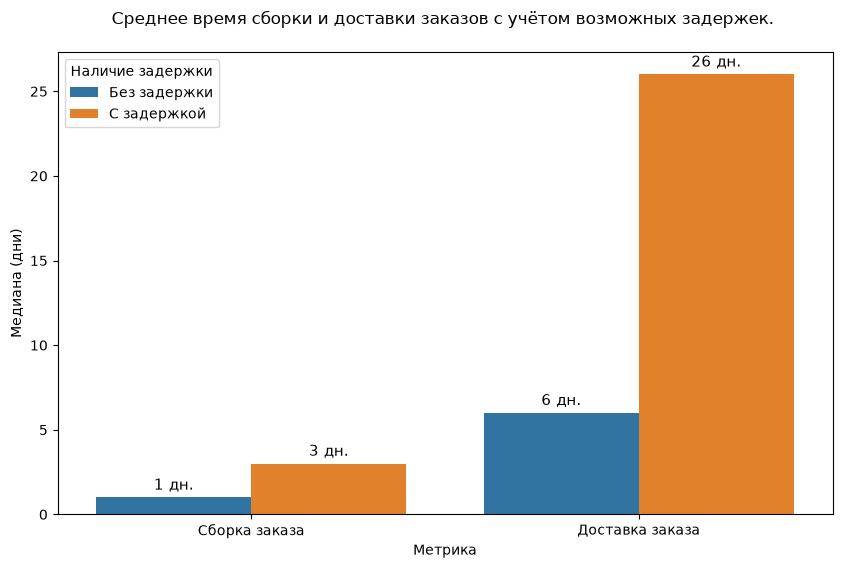

In [42]:
# Построим график
fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(data=is_delay_long, x='metric', y='median_days', hue='is_delay_label', ax=ax)

for container in ax.containers:
    ax.bar_label(container, fmt='%.0f дн.', padding=3, fontsize=11)

plt.title('Среднее время сборки и доставки заказов с учётом возможных задержек. \n')
plt.xlabel('Метрика')
plt.ylabel('Медиана (дни)')
plt.xticks([0, 1], ['Сборка заказа', 'Доставка заказа'])
plt.legend(title='Наличие задержки')
plt.savefig('images/delivery_time.png', dpi=150, bbox_inches='tight')
plt.show()

**Выводы по задаче:** 
- ~97% клиентов совершают только один заказ. Это ключевой сигнал отсутствия PMF. В здоровом маркетплейсе доля повторных покупателей — 30–50%, здесь — менее 3%.
- Среднее время доставки — 9 дней, что выглядит довольно большим сроком, в сочетании с 6,77% задержек создаёт негативный опыт у части клиентов. При задержке она растёт в среднем на 7 дней, то есть клиент ждёт товар почти в два раза дольше.
- Основная часть задержек формируется на этапе доставки, а не на этапе сборки заказа. Значит, корень проблемы — в логистических партнёрах, а не в работе склада.
- Проблема не в цене и не в ассортименте: клиенты делают первую покупку охотно, но не возвращаются. Это классический признак того, что первый опыт не оправдывает ожиданий.

**Итог:** PMF отсутствует. Продукт решает разовую задачу («купить бразильский товар»), но не становится привычным каналом покупок. Для достижения PMF нужно сначала исправить клиентский опыт — иначе любые вложения в рост приведут только к росту оттока.

**Рекомендации:**
- Повысить retention до 5–10% прежде, чем масштабировать маркетинг.
- Сократить среднее время доставки и уменьшить долю задержек, работая с логистическими партнёрами.
- Начать работу над возвратом клиентов.

### Задача 3. Определить основные метрики.
Определим 5 основных метрик, на которых продакту можно сконцентрироваться, чтобы максимизировать прибыль компании:
- **Количество доставленных заказов** - показывает увеличение объема продаж на маркетплейсе.
- **Количество уникальных пользователей, совершающих покупки** (Monthly Active Buyers) - показывает объем аудитории, которой продукт доставляет ценность.
- **Конверсия в платящего** - показывает заинтересованность новых клиентов в продукте.
- **Месячный Retention** -  показывает вовлеченность клиента в продолжение использования продукта.
- **LTV** - показывает денежное выражение вовлеченности клиента.

Визуализируем первую, вторую, четвёртую и пятую метрики, используя месячную гранулярность и окно в 1 месяц.

In [43]:
# Посчитаем количество доставленных заказов по месяцам.
delivered_orders_count = delivered_orders.groupby('order_period').order_id.nunique().loc['2017-01':]

In [44]:
# Посчитаем количество уникальных пользователей, совершающих покупки по месяцам.
monthly_active_buyers = delivered_orders.groupby('order_period').customer_unique_id.nunique().loc['2017-01':]

In [45]:
# Посчитаем total_price для каждого заказа
order_price = order_items.groupby('order_id').agg(total_price = ('price', 'sum')).reset_index()

In [46]:
# Присоеденим order_price к delivered_orders по полю order_id
delivered_orders = pd.merge(delivered_orders,
                            order_price,
                            on='order_id',
                            how='left'
                           )

In [47]:
# Посчитаем сумму заказов в когортах по месецам
cohort_total_price = (delivered_orders.groupby(['cohort', 'period_number_month'])
                                      .total_price.sum()
                                      .reset_index()
                     )

In [48]:
# Развернем таблицу и посчитаем LTV
ltv = cohort_total_price.pivot(index='cohort',
                               columns='period_number_month',
                               values='total_price'
                              )

In [49]:
# Посчитаем среднее LTV на одного пользователя.
ltv_per_user = ltv.divide(cohort_size, axis=0)

In [50]:
# Посчитаем кумулятивный LTV для когорт по месяцам.
ltv_cumulative = ltv_per_user.cumsum(axis=1)

In [51]:
# Отфильтуем данные оставив с '2017-01' по '2018-07' когорты
ltv_cumulative = ltv_cumulative.loc['2017-01':'2018-07']
ltv_cumulative

period_number_month,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,19,20
cohort,,,,,,,,,,,,,,,,,,,,
2017-01,148.653537,148.819654,148.929880,149.029614,149.295173,149.374947,149.870891,149.977008,150.011449,NaN,150.507593,150.572753,151.179322,151.576662,151.640492,151.760040,151.977992,152.403245,152.453777,NaN
2017-02,138.519811,138.802876,139.089562,139.142373,139.721201,139.750781,140.096278,140.235266,140.491361,140.660450,140.849148,141.075645,141.221799,141.387361,141.472450,141.541680,141.690675,141.950651,NaN,NaN
2017-03,139.493419,140.074461,140.639315,141.279164,141.663967,142.172326,142.403240,142.690163,143.167756,143.248071,143.481879,143.600914,143.914119,143.979809,144.220066,144.456783,144.517028,144.667044,NaN,NaN
2017-04,145.598422,146.733273,147.077523,147.366030,147.813467,148.263523,149.051768,149.453424,149.823135,150.012163,150.255634,150.369398,150.562473,150.670860,150.781742,150.872817,151.257716,NaN,NaN,NaN
2017-05,136.955247,137.391423,138.108359,138.546315,138.853739,139.242310,139.999740,140.152663,140.543109,140.842415,141.176738,141.503555,141.782962,141.796207,141.975998,142.158339,NaN,NaN,NaN,NaN
2017-06,134.395625,134.911876,135.451219,135.850525,136.237305,136.682724,137.084294,137.298043,137.386921,137.522502,138.204088,138.762621,138.887963,139.151438,139.846373,NaN,NaN,NaN,NaN,NaN
2017-07,124.291572,124.972486,125.252117,125.515110,125.753791,126.186413,126.771306,126.821777,126.888828,127.369084,127.632478,127.886062,128.219471,128.397834,NaN,NaN,NaN,NaN,NaN,NaN
2017-08,132.170082,133.204165,133.665470,133.860322,134.216680,134.830320,135.215218,135.602772,135.997855,136.256397,136.535048,136.945615,137.067860,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2017-09,146.695232,147.428005,148.120947,148.465352,149.167558,149.568437,149.782442,149.977593,150.225418,150.343750,150.615575,150.678255,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


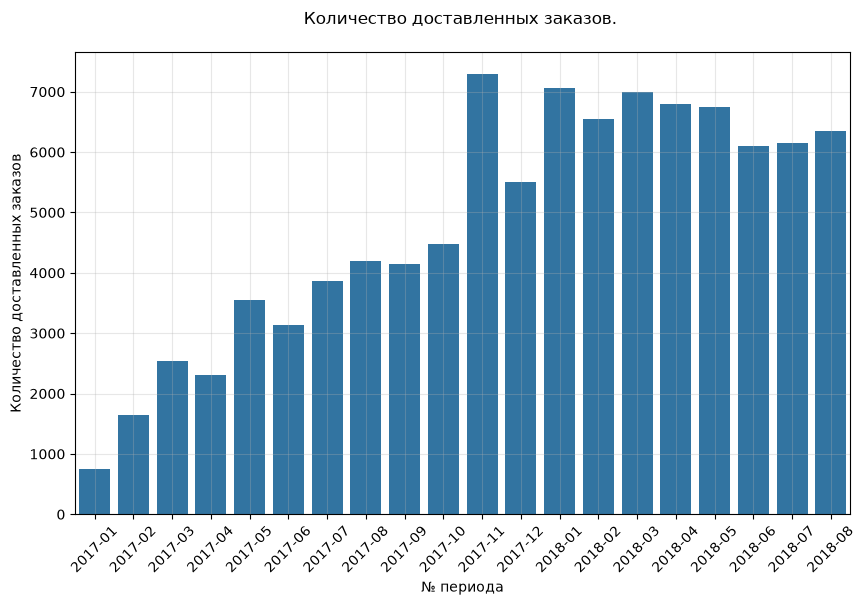

In [52]:
# Построим график количества доставленных заказов по месяцам.
fig, ax = plt.subplots(figsize=(10, 6))

# Преобразуем Series в DataFrame или передаём явно x/y
sns.barplot(x=delivered_orders_count.index, y=delivered_orders_count.values, ax=ax)

ax.grid(True, alpha=0.3)
plt.title('Количество доставленных заказов. \n')
ax.set_xlabel('№ периода')
ax.set_ylabel('Количество доставленных заказов')
plt.xticks(rotation=45)

plt.savefig('images/delivered_orders.png', dpi=150, bbox_inches='tight')
plt.show()

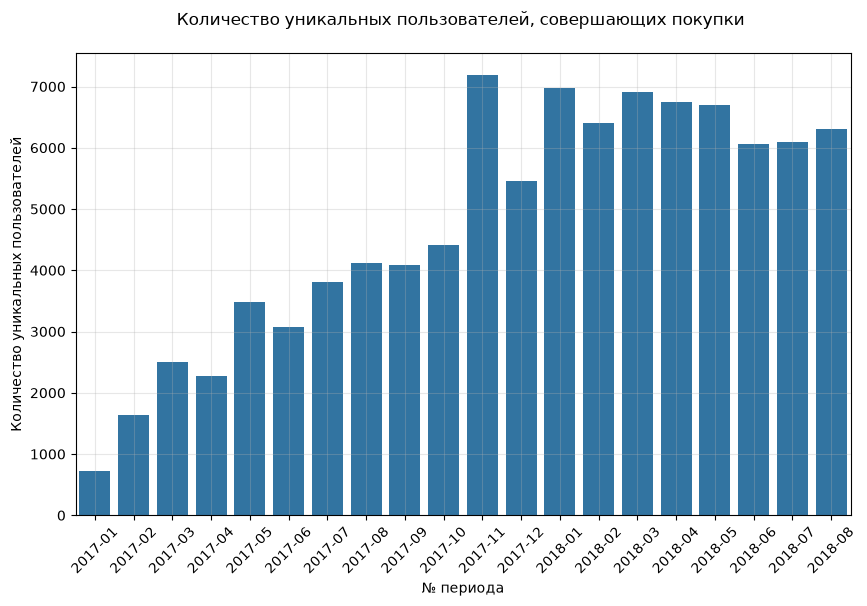

In [53]:
# Построим график количества уникальных пользователей, совершающих покупки по месяцам.
fig, ax = plt.subplots(figsize=(10, 6))

# Преобразуем Series в DataFrame или передаём явно x/y
sns.barplot(x=monthly_active_buyers.index, y=monthly_active_buyers.values, ax=ax)

ax.grid(True, alpha=0.3)
plt.title('Количество уникальных пользователей, совершающих покупки \n')
ax.set_xlabel('№ периода')
ax.set_ylabel('Количество уникальных пользователей')
plt.xticks(rotation=45)

plt.savefig('images/monthly_active_buyers.png', dpi=150, bbox_inches='tight')
plt.show()

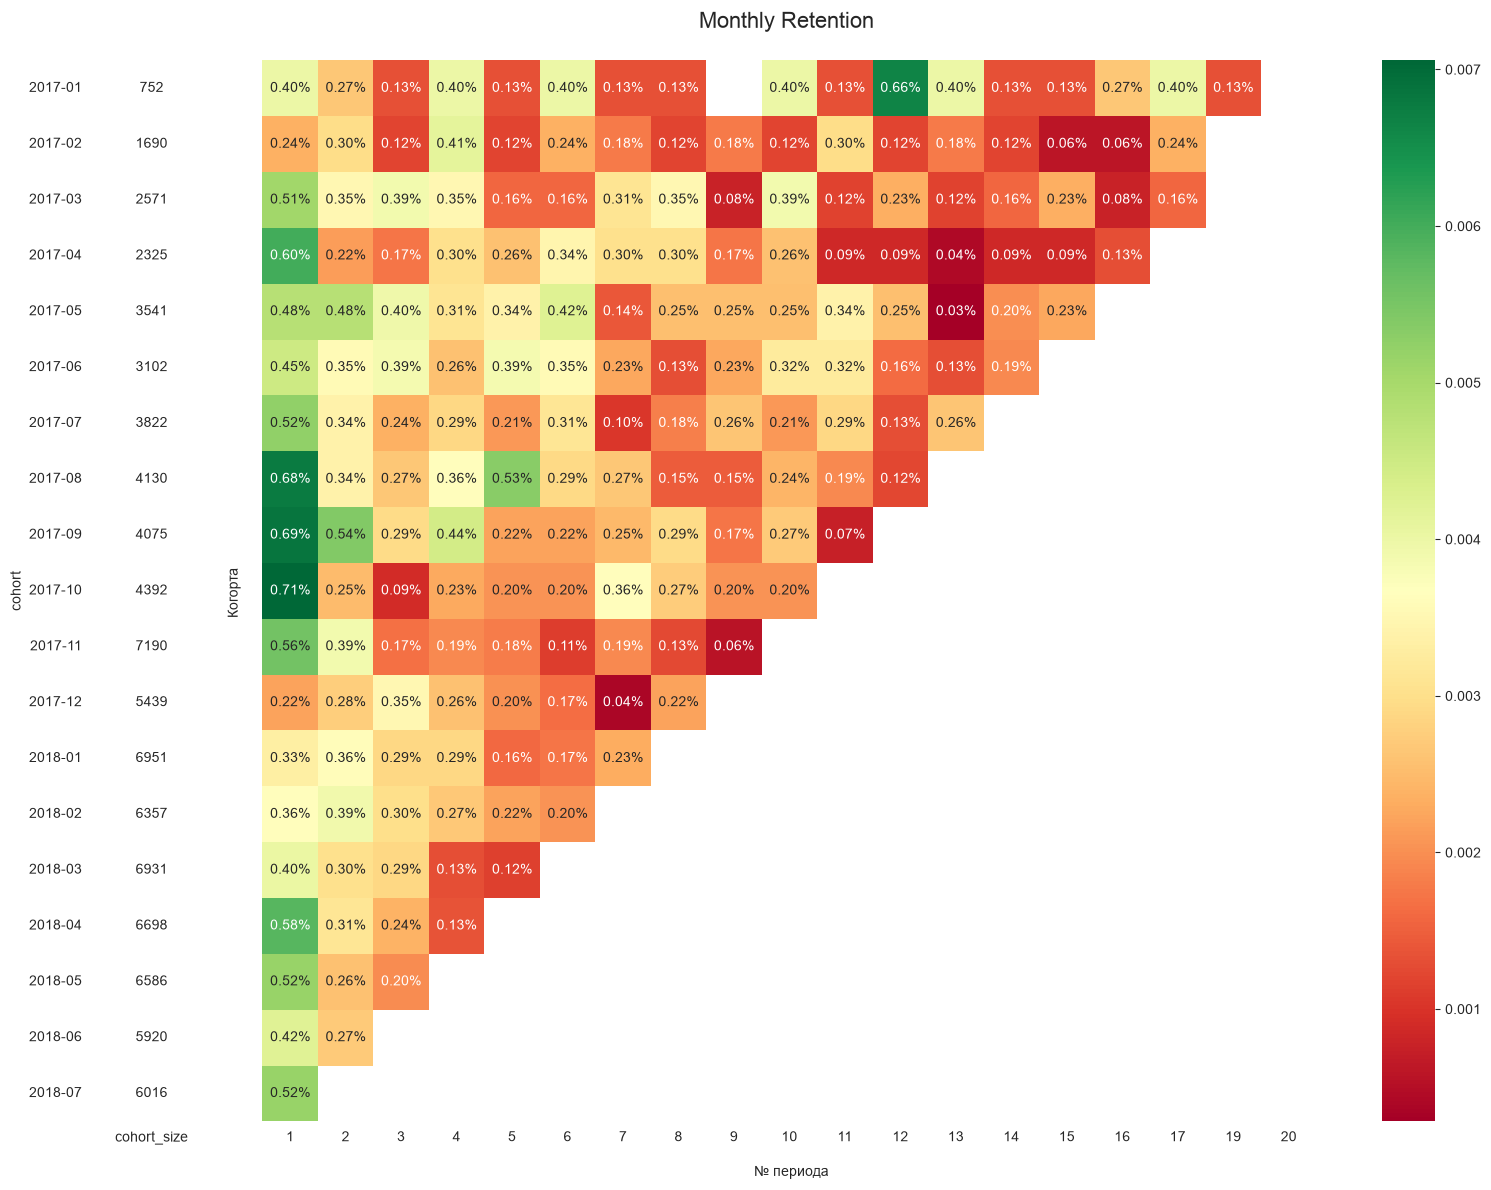

In [54]:
# Построим тепловую карту когортного анализа Retention
with sns.axes_style("white"):
    fig, ax = plt.subplots(1, 2, figsize=(16, 12), sharey=True, gridspec_kw={'width_ratios': [1, 11]})

    # Тепловая карта для коэффициентов удержания
    sns.heatmap(retention_matrix.iloc[:, 1:],
                mask=retention_matrix.iloc[:, 1:].isnull(),
                annot=True,
                fmt='.2%',
                cmap='RdYlGn',
                ax=ax[1])
    ax[1].set_title('Monthly Retention \n', fontsize=16)
    ax[1].set(xlabel='\n № периода', ylabel='Когорта \n')

    # Тепловая карта для размеров когорт
    cohort_size_df = pd.DataFrame(cohort_size).rename(columns={0: 'cohort_size'})
    white_cmap = mcolors.ListedColormap(['white'])
    sns.heatmap(cohort_size_df,
                annot=True,
                cbar=False,
                fmt='g',
                cmap=white_cmap,
                ax=ax[0])

    fig.tight_layout()
    plt.show()

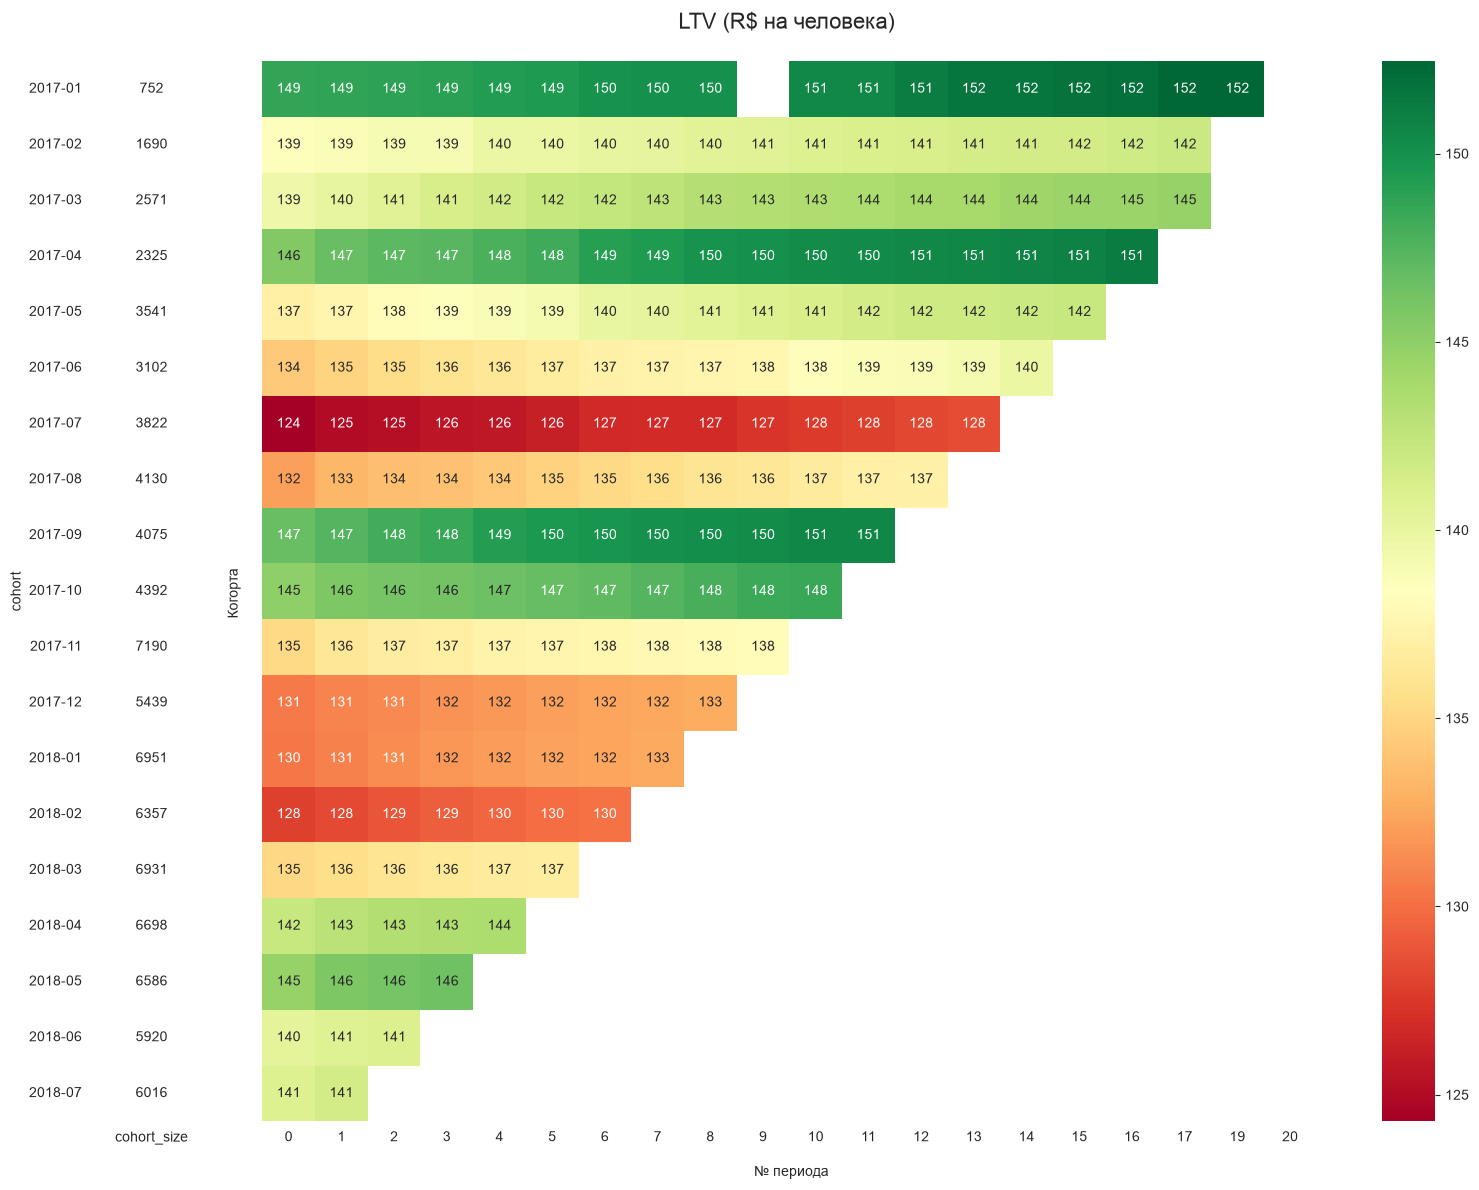

In [55]:
# Построим тепловую карту когортного анализа LTV
with sns.axes_style("white"):
    fig, ax = plt.subplots(1, 2, figsize=(16, 12), sharey=True, gridspec_kw={'width_ratios': [1, 11]})

    # Тепловая карта для LTV
    sns.heatmap(ltv_cumulative,
                mask=ltv_cumulative.isnull(),
                annot=True,
                fmt='.0f',
                cmap='RdYlGn',  #'Blues'  'RdYlGn'
                ax=ax[1])
    ax[1].set_title('LTV (R$ на человека) \n', fontsize=16)
    ax[1].set(xlabel='\n № периода', ylabel='Когорта \n')

    # Тепловая карта для размеров когорт
    cohort_size_df = pd.DataFrame(cohort_size).rename(columns={0: 'cohort_size'})
    white_cmap = mcolors.ListedColormap(['white'])
    sns.heatmap(cohort_size_df,
                annot=True,
                cbar=False,
                fmt='g',
                cmap=white_cmap,
                ax=ax[0])

    fig.tight_layout()
    plt.savefig('images/ltv_heatmap.png', dpi=150, bbox_inches='tight')
    plt.show()

**Выводы по задаче:**
- Количество доставленных заказов — базовая метрика объёма продаж. Рост этой метрики при стабильном retention означает рост бизнеса.
- Количество уникальных покупателей (MAB) — отражает объём аудитории, которой продукт доставляет ценность. Если MAB растёт, а количество заказов — нет, значит клиенты не возвращаются.
- Конверсия в платящего — показывает, насколько хорошо продукт убеждает новых клиентов совершить первую покупку.
- Месячный retention — ключевая метрика удержания. Именно она сейчас «болит» сильнее всего.
- LTV — денежное выражение ценности клиента. Кумулятивный LTV по когортам показывает, что клиент приносит ~150 R$ за всю жизнь и практически не увеличивает эту сумму после первого месяца.

**Итог:** все пять метрик взаимосвязаны. Сейчас «узкое горлышко» — retention и LTV. Улучшение этих двух метрик автоматически потянет за собой остальные.

### Задача 4. Выбрать одну из 3 основных гипотез с помощью фреймворка ICE.
**Гипотеза 1:** Если исправим баг в системе процессинга заказов, то клиентам не придётся сталкиваться с проблемой отмены заказа, вследствие чего количество доставленных заказов увеличится. Считаем, что мы таким образом избавимся от всех отмен.  
Confidence: 8, Easy: 6.

**Гипотеза 2:** Если сократим время до отгрузки заказа, то клиенты перестанут получать свой заказ с запаздыванием, вследствие чего количество заказов увеличится за счёт повторных заказов.   
Confidence: 10, Easy: 4.

**Гипотеза 3:** Если создадим новый способ оплаты, который будет конвертировать клиентов в повторный заказ, то клиенты не будут испытывать трудности при оформлении заказа, вследствие чего количество заказов увеличится за счёт повторных заказов тех, кто раньше не делал повторный заказ.   
Confidence: 5, Easy: 9.

Для расчёта Impact возьмем данные с июня 2017 года. Будем считать, что конверсия в повторный заказ равна величине медианного retention 1-го месяца (см. пункт 1 проекта).

Для перевода метрики в Impact воспользуйтесь следующей шкалой:  
|**Impact**          |   1  |   2   |    3    |    4    |    5     |     6     |     7     |     8      |      9      |      10     |
|--------------------|------|-------|---------|---------|----------|-----------|-----------|------------|-------------|-------------|
|**Значение метрики**| 0-50 | 51-150| 151-350 | 351-750 | 751-1550 | 1551-3150 | 3151-6350 | 6351-12750 | 12751-25550 |	25551-51150 |

In [56]:
# Создадим DF с метриками наших гипотез
hypotheses = pd.DataFrame({'acquired_customers': [pd.NA, pd.NA, pd.NA],
                           'impact':             [pd.NA, pd.NA, pd.NA],
                           'confidence':         [8, 10, 5],
                           'easy':               [6, 4, 9],
                           'ICE':                [pd.NA, pd.NA, pd.NA]},
                          index = ['Гипотеза 1', 'Гипотеза 2', 'Гипотеза 3'])

In [57]:
# Зададим конверсию на уровне медианы retention 1-го месяца, который считали в Задаче №1
conversion = retention_matrix.iloc[:, 1].median()

In [58]:
# Для первой гипотезы возьмем данные с июня 2017 года
data_hypotheses_1 = data[data.order_purchase_timestamp.dt.to_period('M') >= '2017-06']

In [59]:
# Посчитаем количество потенциальных пользователей для первой гипотезы
hypotheses.loc['Гипотеза 1', 'acquired_customers'] = (data_hypotheses_1.query("order_status in ['canceled', 'unavailable']")
                                                                       .order_id.nunique()
                                                     )

In [60]:
# Для второй гипотезы возьмем данные по доставленным заказам
# Отфильтруем по дате заказ начиная с июня 2017 года
data_hypotheses_2 = delivered_orders.query("order_period >= '2017-06'")

In [61]:
# Посчитаем количество уникальных клиентов, у которых была задержана доставка заказа.
# Умножим это значение на conversion, округлим до целого числа.
hypotheses.loc['Гипотеза 2', 'acquired_customers'] = (
    round(data_hypotheses_2.query('is_delay == True')
        .customer_unique_id
        .nunique()
          * conversion,
          0)
        .astype('int')
)

In [62]:
# Для третьей гипотезы возьмем данные по неотмененным заказам.
# Отфильтруем по дате заказ начиная с июня 2017 года
data_hypotheses_3 = non_cancelled_orders.query("order_period >= '2017-06'")

In [63]:
# Посчитаем количество заказов для каждого пользователя. 
# Потом посчитаем количество пользователей по количеству совершенных заказов.
# Возьмем количество пользователей, у которых совершен только один заказ, и умножим на конверсию.
# Округлим до целого числа.
hypotheses.loc['Гипотеза 3', 'acquired_customers'] = (
    round(data_hypotheses_3.groupby('customer_unique_id')
        .order_id
        .count()
        .value_counts()[1]
          * conversion,
          0)
    .astype('int')
)

In [64]:
# Посчитаем impact для гипотез.
hypotheses['impact'] = (pd.cut(hypotheses.acquired_customers,
                              bins=[0, 50, 150, 350, 750, 1550, 3150, 6350, 12750, 25550, 51150],
                              labels=range(1, 11),
                              right=True)
                        .astype('int')
                       )

In [65]:
# Посчитаем ICE для гипотез
hypotheses['ICE'] = hypotheses.impact * hypotheses.confidence * hypotheses.easy

In [66]:
hypotheses

,acquired_customers,impact,confidence,easy,ICE
Гипотеза 1,974,5,8,6,240
Гипотеза 2,31,1,10,4,40
Гипотеза 3,414,4,5,9,180


**Выводы по задаче:**
- **Гипотеза 1** (исправление бага в процессинге) набирает ICE = 240 — максимальный балл. Она даёт самый большой прирост клиентов (974) при умеренных усилиях. Логика простая: если устранить техническую причину отмен, заказы дойдут до клиента, и часть из них станет повторными.
- **Гипотеза 2** (сокращение времени отгрузки) — ICE = 40. Несмотря на высокую уверенность (10), низкий Impact (1) и сложность реализации (Easy = 4) делают её неприоритетной на текущем этапе.
- **Гипотеза 3** (новый способ оплаты) — ICE = 180. Хорошая идея на будущее, но требует проверки гипотезы о том, что клиенты действительно не возвращаются из-за сложностей с оплатой. Данных для этого пока недостаточно.

**Итог:** по фреймворку ICE выбираем Гипотезу 1 — исправление бага в процессинге заказов. Это даёт максимальный эффект при минимальном риске и не требует изменений в клиентском опыте.

### Задача 5: Сформулировать нужные метрики, на которые гипотеза должна повлиять.

**Гипотеза:** Если исправим баг в системе процессинга заказов, то клиентам не придётся сталкиваться с проблемой отмены заказа, вследствие чего количество доставленных заказов увеличится. Считаем, что мы таким образом избавимся от всех отмен.  

**Метрики:**
- Целевые: доля доставленных заказов от всех созданных, количество доставленных заказов на одного пользователя. Эти метрики помогают нам понять, насколько эффективны наши действия по совершенствованию продукта и стимулированию пользователей к более частым покупкам. Кроме того, они не зависят от сезонных колебаний.
- Прокси: доля отмененных заказов от всех созданных, количество отмененных заказов на одного пользователя. Эти метрики напрямую отражают наши изменения в продукте и не подвержены сезонным колебаниям.
- Guardrail: общее количество заказов, retention, конверсия из корзины в создание заказа.  Эти метрики свидетельствуют о том, что мы не нарушили процесс оплаты и оформления, а также не ухудшили пользовательский опыт. 

### Задача 6: Сформулировать выводы о проделанной работе и составить отчет.

**Главный вывод**  

Маркетплейс не достиг product/market fit. Продукт привлекает клиентов, но не удерживает их: 97% покупателей совершают только один заказ, retention 1-го месяца — 0,51%. Причины — не в цене и не в ассортименте, а в клиентском опыте: клиенты сталкиваются с задержками доставки и отменами заказов.

**Что это значит для бизнеса**
- Рост через маркетинг не работает. Пока retention ниже 1%, привлечение новых клиентов лишь увеличивает отток. Каждый вложенный в рекламу рубль не окупается.
- Улучшение продукта важнее масштабирования. Прежде чем увеличивать бюджет на привлечение, нужно довести retention хотя бы до 5–10%.
- Корень проблемы — в операционных процессах. 6,77% задержек и высокая доля отмен — это не «мелкие баги», а системные сбои, которые напрямую влияют на LTV.

**Что делать**
- Реализовать Гипотезу 1 — исправить баг в процессинге заказов. Это даст быстрый и измеримый эффект.
- Запустить мониторинг метрик — целевых (доля доставленных), прокси (доля отменённых) и guardrail (retention, конверсия).
- Проверить эффект через 2–3 месяца — сравнить retention и LTV до и после релиза.
- Если эффект подтвердится — перейти к Гипотезе 3 (новый способ оплаты) для стимулирования повторных покупок.
- Параллельно работать с логистикой — сокращать время доставки и уменьшать долю задержек. Это долгий, но необходимый процесс.

**Ограничения анализа**
- Данные охватывают 2016–2018 годы. Рынок и поведение клиентов могли измениться.
- Retention считался по неотменённым заказам — если часть отмен не фиксируется в данных, реальный retention может быть ниже.
- Гипотезы оценены по ICE, но без A/B-теста нельзя гарантировать, что выбранная гипотеза даст ожидаемый эффект.

**Следующие шаги**  

Реализовать Гипотезу 1, настроить дашборд с целевыми, прокси и guardrail метриками, через 2–3 месяца провести повторную оценку retention и PMF. Если retention вырастет хотя бы до 5%, можно переходить к масштабированию.

# Отчёт по продуктовой аналитике маркетплейса

## Введение

Я, как аналитик данных, провел анализ нового маркетплейса по продаже бразильских товаров. Цель работы — оценить текущее состояние продукта, выявить проблемы и предложить точку роста для увеличения прибыли. В ходе анализа использовались данные о заказах, клиентах и товарах за период с 2016 по 2018 год. Инструменты: Python (pandas, seaborn, matplotlib).

---

## Задача 1. Когортный анализ Retention

Был рассчитан месячный retention по неотмененным заказам (исключены статусы `canceled` и `unavailable`). Дата заказа — `order_purchase_timestamp`. Когорта присваивалась по первому месяцу покупки клиента.

<a id="fig1"></a>
![Тепловая карта Retention](images/retention_heatmap.png)
*Рис. 1. Тепловая карта Retention по когортам*

<a id="fig2"></a>
![Медианный Retention по месяцам](images/median_retention.png)
*Рис. 2. Медианный Retention по месяцам*

**Выводы:**
- Медиана retention 1-го месяца составила **0,51%**, что крайне мало.
- Наибольший retention 3-го месяца наблюдается в когорте мая 2017 года.
- Продукт обладает очень слабым удержанием.

---

## Задача 2. Оценка Product/Market Fit

PMF фактически отсутствует: retention 1-го месяца < 1%.

Анализ распределение клиентов по числу заказов показал, что **~97% клиентов совершают только один заказ**.

Дополнительный анализ логистики показал следующие результаты:
- медиана времени доставки — 9 дней;
- доля задержанных заказов — 6,77%;
- медиана задержки — 7 дней.

<a id="fig3"></a>
![Время сборки и доставки](images/delivery_time.png)
*Рис. 3. Сравнение времени сборки и доставки для заказов с задержкой и без*

**Выводы:** PMF отсутствует. Основная часть задержек приходится на этап доставки.

**Рекомендации:** до масштабирования повысить retention, сократить среднее время доставки и уменьшить долю задержанных заказов.

---

## Задача 3. Ключевые метрики

Определены 5 метрик, на которых стоит сфокусироваться продакту:

1. Количество доставленных заказов.
2. Количество уникальных покупателей (Monthly Active Buyers).
3. Конверсия в платящего.
4. Месячный retention.
5. LTV.

Построены графики динамики по месяцам и тепловая карта кумулятивного LTV по когортам.

<a id="fig4"></a>
![Количество доставленных заказов](images/delivered_orders.png)
*Рис. 4. Количество доставленных заказов по месяцам*

<a id="fig5"></a>
![Уникальные покупатели](images/monthly_active_buyers.png)
*Рис. 5. Количество уникальных покупателей по месяцам*

<a id="fig6"></a>
![Кумулятивный LTV](images/ltv_heatmap.png)
*Рис. 6. Кумулятивный LTV по когортам (R$ на человека)*

Повторно приведём тепловую карту retention как ключевую метрику вовлечённости

<a id="fig7"></a>
![Retention как ключевая метрика](images/retention_heatmap.png)
*Рис. 7. Retention как ключевая метрика вовлечённости*

---

## Задача 4. Выбор гипотезы по ICE

Рассмотрены три гипотезы:

- **Гипотеза 1.** Исправление бага в процессинге заказов → снижение отмен. Confidence = 8, Easy = 6.
- **Гипотеза 2.** Сокращение времени отгрузки → снижение задержек. Confidence = 10, Easy = 4.
- **Гипотеза 3.** Новый способ оплаты для повторных заказов. Confidence = 5, Easy = 9.

Для расчёта Impact взяты данные с июня 2017 года, конверсия = медиана retention 1-го месяца.

| Гипотеза | acquired_customers | Impact | Confidence | Easy | ICE |
|---|---:|---:|---:|---:|---:|
| Гипотеза 1 | 974 | 5 | 8 | 6 | **240** |
| Гипотеза 2 | 31 | 1 | 10 | 4 | 40 |
| Гипотеза 3 | 414 | 4 | 5 | 9 | 180 |

**Вывод:** по фреймворку ICE выбираем **Гипотезу 1** — исправление бага в процессинге заказов.

---

## Задача 5. Метрики для выбранной гипотезы

**Гипотеза:** исправление бага в процессинге заказов → клиенты перестанут сталкиваться с отменой заказа → количество доставленных заказов увеличится.

**Метрики:**
- **Целевые:** доля доставленных заказов от всех созданных; количество доставленных заказов на пользователя.
- **Прокси:** доля отменённых заказов от всех созданных; количество отменённых заказов на пользователя.
- **Guardrail:** общее количество заказов; retention; конверсия из корзины в создание заказа.

---

## Задача 6. Выводы

Маркетплейс находится на ранней стадии, PMF не достигнут. Критически низкий retention и высокая доля одиночных покупок указывают на проблемы клиентского опыта, особенно в логистике и обработке заказов. Приоритетная гипотеза — устранение бага в процессинге, что должно увеличить количество доставленных заказов.

**Следующие шаги:** реализация гипотезы, мониторинг целевых, прокси и guardrail метрик, повторная оценка retention и PMF.